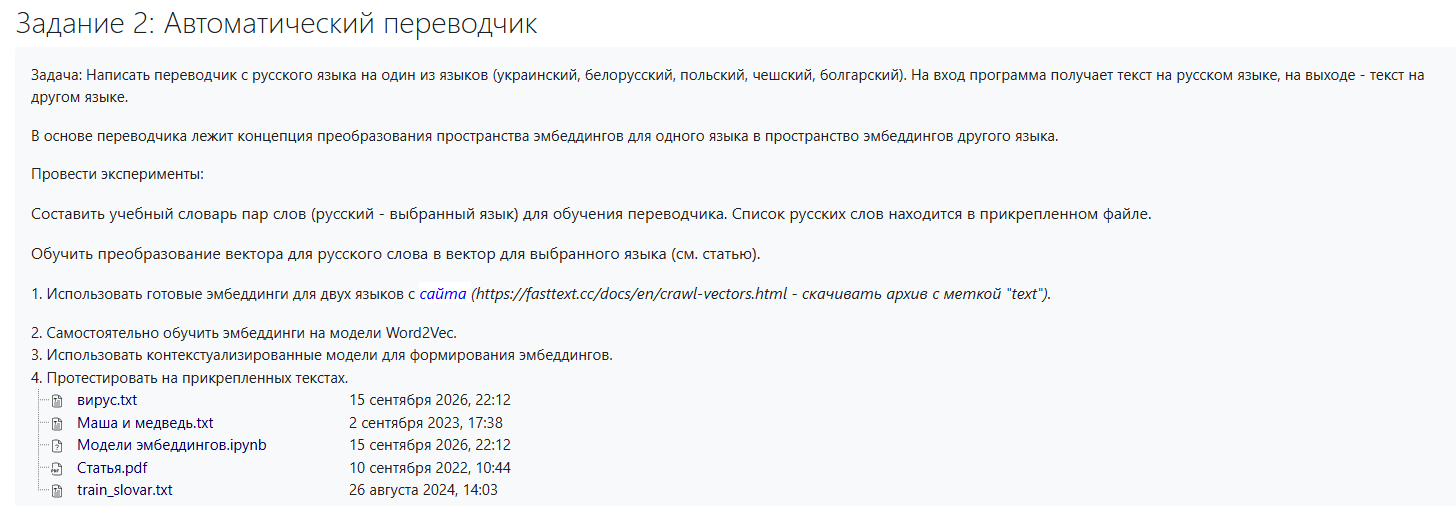

# Готовые эмбединги

In [2]:
import re
import numpy as np
import pandas as pd
from gensim.models import KeyedVectors
from numpy.linalg import svd
import matplotlib.pyplot as plt

In [4]:
from gensim.models import KeyedVectors

# Один раз (медленно, но только один раз)
ru_vec = KeyedVectors.load_word2vec_format('cc.ru.300.vec', binary=False)
be_vec = KeyedVectors.load_word2vec_format('cc.be.300.vec', binary=False)

ru_vec.save('cc.ru.300.kv')
be_vec.save('cc.be.300.kv')

In [5]:
ru_vec = KeyedVectors.load('cc.ru.300.kv', mmap='r')
be_vec = KeyedVectors.load('cc.be.300.kv', mmap='r')

In [7]:
with open('train_slovar.txt', encoding='utf-8') as f:
    ru_words = [w.strip().lower() for w in f if w.strip()]
ru_words = list(dict.fromkeys(ru_words))
print(len(ru_words))

1876


In [8]:
# Учебный словарь русский → белорусский.
# При необходимости можно расширить вручную.
RAW_PAIRS = [
    ('вероятно', 'верагодна'), ('существует', 'існуе'),
    ('экзамен', 'экзамен'), ('или', 'або'), ('ли', 'ці'),
    ('совершенно', 'цалкам'), ('совсем', 'зусім'),
    ('автомобиль', 'аўтамабіль'), ('вагон', 'вагон'),
    ('администрация', 'адміністрацыя'), ('адрес', 'адрас'),
    ('академик', 'акадэмік'), ('академия', 'акадэмія'),
    ('артист', 'артыст'), ('аккуратно', 'акуратна'),
    ('действие', 'дзеянне'), ('акция', 'акцыя'),
    ('но', 'але'), ('американец', 'амерыканец'),
    ('анализ', 'аналіз'), ('арест', 'арышт'),
    ('листы', 'лісты'), ('войско', 'войска'),
    ('признак', 'прыкмета'), ('белье', 'бялізна'),
    ('гораздо', 'значна'), ('много', 'многа'),
    ('база', 'база'), ('танк', 'танк'),
    ('родители', 'бацькі'), ('родина', 'радзіма'),
    ('отец', 'бацька'), ('видеть', 'бачыць'),
    ('безопасность', 'бяспека'), ('март', 'сакавік'),
    ('библиотека', 'бібліятэка'), ('бег', 'бег'),
    ('беда', 'бяда'), ('более', 'больш'),
    ('большинство', 'большасць'), ('блеск', 'бляск'),
    ('боец', 'баец'), ('больно', 'балюча'),
    ('долг', 'доўг'), ('борьба', 'барацьба'),
    ('бровь', 'брыво'), ('грязь', 'гразь'),
    ('штаны', 'штаны'), ('быть', 'быць'),
    ('тревога', 'трывога'), ('здание', 'будынак'),
    ('строить', 'будаваць'), ('любой', 'любы'),
    ('куст', 'куст'), ('вес', 'вага'),
    ('масса', 'маса'), ('тяжело', 'цяжка'),
    ('грузовик', 'грузавік'), ('вариант', 'варыянт'),
    ('значение', 'значэнне'), ('стоимость', 'кошт'),
    ('стоить', 'каштаваць'), ('твой', 'твой'),
    ('убивать', 'забіваць'), ('убийство', 'забойства'),
    ('убийца', 'забойца'), ('считать', 'лічыць'),
    ('вежливо', 'ветліва'), ('вслух', 'уголас'),
    ('медведь', 'мядзведзь'), ('громадный', 'велізарны'),
    ('сентябрь', 'верасень'), ('версия', 'версія'),
    ('правило', 'правіла'), ('свадьба', 'вяселле'),
    ('ужин', 'вячэра'), ('вообще', 'наогул'),
    ('выбор', 'выбар'), ('выборы', 'выбары'),
    ('выбрать', 'выбраць'), ('взрыв', 'выбух'),
    ('вынуть', 'выняць'), ('вывести', 'вывесці'),
    ('вытащить', 'выцягнуць'), ('изучать', 'вывучаць'),
    ('придумать', 'прыдумаць'), ('выдавать', 'выдаваць'),
    ('выдать', 'выдаць'), ('снимать', 'здымаць'),
    ('выехать', 'выехаць'), ('выбросить', 'выкінуць'),
    ('вызов', 'выклік'), ('выполнять', 'выконваць'),
    ('использование', 'выкарыстанне'),
    ('пользоваться', 'карыстацца'),
    ('требование', 'патрабаванне'), ('появление', 'з\'яўленне'),
    ('случайный', 'выпадковы'), ('случай', 'выпадак'),
    ('выпить', 'выпіць'), ('пить', 'піць'),
    ('выражение', 'выраз'), ('разрешить', 'дазволіць'),
    ('решать', 'вырашаць'), ('производство', 'вытворчасць'),
    ('выразить', 'выразіць'), ('вывод', 'вывад'),
    ('заключение', 'заключэнне'), ('высоко', 'высока'),
    ('высота', 'вышыня'), ('выставка', 'выстаўка'),
    ('довольно', 'даволі'), ('выступление', 'выступленне'),
    ('воспитание', 'выхаванне'), ('происходить', 'адбывацца'),
    ('посетитель', 'наведвальнік'), ('отдел', 'аддзел'),
    ('открывать', 'адкрываць'), ('открыть', 'адкрыць'),
    ('открытие', 'адкрыццё'), ('эхо', 'рэха'),
    ('отличие', 'адрозненне'), ('отказ', 'адмова'),
    ('падать', 'падаць'), ('родственник', 'сваяк'),
    ('внимание', 'увага'), ('ответственность', 'адказнасць'),
    ('соответствовать', 'адпавядаць'), ('ответ', 'адказ'),
    ('отдыхать', 'адпачываць'), ('отдых', 'адпачынак'),
    ('отправить', 'адправіць'), ('послать', 'паслаць'),
    ('отпуск', 'водпуск'), ('ведро', 'вядро'),
    ('процент', 'працэнт'), ('расстояние', 'адлегласць'),
    ('отсутствие', 'адсутнасць'), ('отчаяние', 'адчай'),
    ('ощущать', 'адчуваць'), ('чувствовать', 'адчуваць'),
    ('ощущение', 'адчуванне'), ('чувство', 'пачуццё'),
    ('виза', 'віза'), ('визит', 'візіт'),
    ('война', 'вайна'), ('военный', 'ваенны'),
    ('окно', 'акно'), ('он', 'ён'),
    ('стихи', 'вершы'), ('восемь', 'восем'),
    ('ветер', 'вецер'), ('вечно', 'вечна'),
    ('указать', 'указаць'), ('указывать', 'указваць'),
    ('включить', 'уключыць'), ('крайне', 'надзвычай'),
    ('власть', 'улада'), ('владелец', 'уладальнік'),
    ('собственность', 'уласнасць'), ('свойство', 'уласцівасць'),
    ('шерсть', 'воўна'), ('воин', 'воін'),
    ('владеть', 'валодаць'), ('волос', 'волас'),
    ('она', 'яна'), ('они', 'яны'),
    ('враг', 'вораг'), ('осень', 'восень'),
    ('вперёд', 'наперад'), ('впервые', 'упершыню'),
    ('влияние', 'уплыў'), ('впечатление', 'уражанне'),
    ('утро', 'раніца'), ('внутри', 'унутры'),
    ('хоть', 'хоць'), ('хотя', 'хоць'),
    ('весь', 'увесь'), ('вставать', 'уставаць'),
    ('успевать', 'паспяваць'), ('убежать', 'уцячы'),
    ('устать', 'стаміцца'), ('потеря', 'страта'),
    ('потерять', 'страціць'), ('терять', 'губляць'),
    ('узел', 'вузел'), ('уши', 'вушы'),
    ('поступок', 'учынак'), ('вчера', 'учора'),
    ('тюрьма', 'турма'), ('ворона', 'варона'),
    ('тыква', 'гарбуз'), ('пушка', 'гармата'),
    ('красиво', 'прыгожа'), ('генеральный', 'генеральны'),
    ('достойный', 'годны'), ('достоинство', 'годнасць'),
    ('ветка', 'галінка'), ('горький', 'горкі'),
    ('горный', 'горны'), ('глубина', 'глыбіня'),
    ('глубоко', 'глыбока'), ('зритель', 'глядач'),
    ('глянуть', 'глянуць'), ('гнать', 'гнаць'),
    ('говорить', 'гаварыць'), ('час', 'гадзіна'),
    ('часы', 'гадзіннік'), ('кормить', 'карміць'),
    ('громко', 'гучна'), ('гордость', 'гордасць'),
    ('гора', 'гара'), ('госпиталь', 'шпіталь'),
    ('господь', 'гасподзь'), ('хозяйка', 'гаспадыня'),
    ('гостиница', 'гасцініца'), ('варить', 'варыць'),
    ('играть', 'гуляць'), ('грозный', 'грозны'),
    ('грех', 'грэх'), ('граждане', 'грамадзяне'),
    ('грубый', 'грубы'), ('группа', 'група'),
    ('отряд', 'атрад'), ('губы', 'вусны'),
    ('пуговица', 'гузік'), ('резина', 'гума'),
    ('девушка', 'дзяўчына'), ('подарок', 'падарунак'),
    ('двадцать', 'дваццаць'), ('двенадцать', 'дванаццаць'),
    ('двигатель', 'рухавік'), ('девять', 'дзевяць'),
    ('куда', 'куды'), ('демократия', 'дэмакратыя'),
    ('десяток', 'дзясятак'), ('дешевый', 'танны'),
    ('источник', 'крыніца'), ('зеркало', 'люстэрка'),
    ('посмотреть', 'паглядзець'), ('дым', 'дым'),
    ('детство', 'дзяцінства'), ('дыхание', 'дыханне'),
    ('дышать', 'дыхаць'), ('дьявол', 'д\'ябал'),
    ('девочка', 'дзяўчынка'), ('дедушка', 'дзядуля'),
    ('действительность', 'рэчаіснасць'), ('верно', 'верна'),
    ('действительно', 'сапраўды'), ('неужели', 'няўжо'),
    ('доставать', 'даставаць'), ('дети', 'дзеці'),
    ('сутки', 'суткі'), ('добиться', 'дабіцца'),
    ('доказывать', 'даказваць'), ('договор', 'дагавор'),
    ('добавить', 'дадаць'), ('пусть', 'хай'),
    ('доказательство', 'доказ'), ('доллар', 'долар'),
    ('договориться', 'дамовіцца'), ('согласиться', 'пагадзіцца'),
    ('допрос', 'допыт'), ('доклад', 'даклад'),
    ('дорогой', 'дарагі'), ('опыт', 'вопыт'),
    ('исследование', 'даследаванне'), ('честно', 'сумленна'),
    ('достижение', 'дасягненне'), ('дойти', 'дайсці'),
    ('мелочь', 'дробязь'), ('второй', 'другі'),
    ('жена', 'жонка'), ('очень', 'вельмі'),
    ('душа', 'душа'), ('экономика', 'эканоміка'),
    ('экран', 'экран'), ('специалист', 'спецыяліст'),
    ('энергия', 'энергія'), ('эпоха', 'эпоха'),
    ('этап', 'этап'), ('европа', 'еўропа'),
    ('европейский', 'еўрапейскі'), ('шутить', 'жартаваць'),
    ('ужасный', 'жудасны'), ('жирный', 'тлусты'),
    ('жить', 'жыць'), ('рожь', 'жыта'),
    ('женщина', 'жанчына'), ('октябрь', 'кастрычнік'),
    ('жесткий', 'жорсткі'), ('жестокий', 'жорсткі'),
    ('печаль', 'сум'), ('журналист', 'журналіст'),
    ('запретить', 'забараніць'), ('забрать', 'забраць'),
    ('забывать', 'забываць'), ('забыть', 'забыць'),
    ('задание', 'заданне'), ('всегда', 'заўсёды'),
    ('генерал', 'генерал'), ('общий', 'агульны'),
    ('гибель', 'гібель'), ('угроза', 'пагроза'),
    ('заяц', 'заяц'), ('обычно', 'звычайна'),
    ('заранее', 'загадзя'), ('заняться', 'заняцца'),
    ('окончание', 'заканчэнне'), ('конец', 'канец'),
    ('звонок', 'званок'), ('близко', 'блізка'),
    ('закрыть', 'зачыніць'), ('зависеть', 'залежаць'),
    ('зависимость', 'залежнасць'), ('оставлять', 'пакідаць'),
    ('остаться', 'застацца'), ('железо', 'жалеза'),
    ('попытка', 'спроба'), ('заменить', 'замяніць'),
    ('вместо', 'замест'), ('заказать', 'замовіць'),
    ('слишком', 'занадта'), ('помнить', 'помніць'),
    ('записать', 'запісаць'), ('запись', 'запіс'),
    ('записка', 'запіска'), ('заплатить', 'заплаціць'),
    ('сейчас', 'зараз'), ('принцип', 'прынцып'),
    ('средство', 'сродак'), ('заснуть', 'заснуць'),
    ('уснуть', 'заснуць'), ('заместитель', 'намеснік'),
    ('замечать', 'заўважаць'), ('охрана', 'ахова'),
    ('защищать', 'абараняць'), ('запад', 'захад'),
    ('спрятать', 'схаваць'), ('захватить', 'захапіць'),
    ('сохранить', 'захаваць'), ('хранить', 'захоўваць'),
    ('собирать', 'збіраць'), ('собрать', 'сабраць'),
    ('строй', 'строй'), ('освобождение', 'вызваленне'),
    ('звание', 'званне'), ('обращение', 'зварот'),
    ('привычка', 'звычка'), ('откуда', 'адкуль'),
    ('отсюда', 'адсюль'), ('оттуда', 'адтуль'),
    ('освободить', 'вызваліць'), ('отчет', 'справаздача'),
    ('обратный', 'адваротны'), ('звучать', 'гучаць'),
    ('согласно', 'згодна'), ('казаться', 'здавацца'),
    ('способность', 'здольнасць'), ('совершить', 'здзейсніць'),
    ('здоровье', 'здароўе'), ('земля', 'зямля'),
    ('земной', 'зямны'), ('зима', 'зіма'),
    ('звезда', 'зорка'), ('съесть', 'з\'есці'),
    ('сломать', 'зламаць'), ('преступник', 'злачынец'),
    ('преступление', 'злачынства'), ('изменение', 'змяненне'),
    ('смена', 'змена'), ('содержание', 'змест'),
    ('знакомство', 'знаёмства'), ('находить', 'знаходзіць'),
    ('знать', 'ведаць'), ('значительный', 'значны'),
    ('внезапно', 'раптам'), ('дно', 'дно'),
    ('снизу', 'знізу'), ('исчезать', 'знікаць'),
    ('исчезнуть', 'знікнуць'), ('опять', 'зноў'),
    ('снова', 'зноў'), ('изображение', 'выява'),
    ('картина', 'карціна'), ('внешний', 'вонкавы'),
    ('тетрадь', 'сшытак'), ('измена', 'здрада'),
    ('образец', 'узор'), ('понятный', 'зразумелы'),
    ('рост', 'рост'), ('остановить', 'спыніць'),
    ('остановка', 'прыпынак'), ('усилие', 'намаганне'),
    ('появиться', 'з\'явіцца'), ('выяснить', 'высветліць'),
    ('игра', 'гульня'), ('император', 'імператар'),
    ('империя', 'імперыя'), ('название', 'назва'),
    ('инженер', 'інжынер'), ('иногда', 'часам'),
    ('иностранец', 'іншаземец'), ('инспектор', 'інспектар'),
    ('институт', 'інстытут'), ('инструмент', 'інструмент'),
    ('интерес', 'інтарэс'), ('другой', 'другі'),
    ('иной', 'іншы'), ('искра', 'іскра'),
    ('существование', 'існаванне'), ('существовать', 'існаваць'),
    ('истинный', 'сапраўдны'), ('рассказ', 'апавяданне'),
    ('столовая', 'сталовая'), ('пища', 'ежа'),
    ('ехать', 'ехаць'), ('идти', 'ісці'),
    ('пойти', 'пайсці'), ('ходить', 'хадзіць'),
    ('кабина', 'кабіна'), ('кофе', 'кава'),
    ('арбуз', 'кавун'), ('сказка', 'казка'),
    ('камера', 'камера'), ('камни', 'камяні'),
    ('шляпа', 'капялюш'), ('столица', 'сталіца'),
    ('капитан', 'капітан'), ('карьера', 'кар\'ера'),
    ('карточка', 'картка'), ('стул', 'крэсла'),
    ('торопиться', 'спяшацца'), ('билет', 'білет'),
    ('апрель', 'красавік'), ('плохо', 'дрэнна'),
    ('голова', 'галава'), ('начальство', 'начальства'),
    ('руководитель', 'кіраўнік'), ('руль', 'руль'),
    ('кивать', 'ківаць'), ('бросать', 'кідаць'),
    ('ковер', 'дыван'), ('китайский', 'кітайскі'),
    ('карман', 'кішэня'), ('комната', 'пакой'),
    ('кость', 'косць'), ('кот', 'кот'),
    ('кошка', 'кошка'), ('класс', 'клас'),
    ('класть', 'класці'), ('клетка', 'клетка'),
    ('книга', 'кніга'), ('книжка', 'кніжка'),
    ('одеяло', 'коўдра'), ('глоток', 'глыток'),
    ('всякий', 'усякі'), ('коллега', 'калега'),
    ('коллектив', 'калектыў'), ('когда', 'калі'),
    ('цвет', 'колер'), ('круг', 'круг'),
    ('кружок', 'гурток'), ('колонна', 'калона'),
    ('командовать', 'камандаваць'), ('насекомое', 'насякомае'),
    ('комиссар', 'камісар'), ('комиссия', 'камісія'),
    ('комитет', 'камітэт'), ('компьютер', 'камп\'ютар'),
    ('коммунист', 'камуніст'), ('конкретный', 'канкрэтны'),
    ('понятие', 'паняцце'), ('конь', 'конь'),
    ('корабль', 'карабель'), ('корреспондент', 'карэспандэнт'),
    ('полезный', 'карысны'), ('польза', 'карысць'),
    ('коричневый', 'карычневы'), ('королева', 'каралева'),
    ('космический', 'касмічны'), ('магазин', 'крама'),
    ('красота', 'прыгажосць'), ('красавица', 'прыгажуня'),
    ('кривой', 'крывы'), ('ледяной', 'ледзяны'),
    ('крыло', 'крыло'), ('крышка', 'вечка'),
    ('кресло', 'крэсла'), ('шаг', 'крок'),
    ('крутой', 'круты'), ('культурный', 'культурны'),
    ('шар', 'шар'), ('покупать', 'купляць'),
    ('уголок', 'куток'), ('кружка', 'кубак'),
    ('пробовать', 'спрабаваць'), ('цепь', 'ланцуг'),
    ('лекция', 'лекцыя'), ('буква', 'літара'),
    ('ноябрь', 'лістапад'), ('горе', 'гора'),
    ('рыцарь', 'рыцар'), ('лишь', 'толькі'),
    ('слева', 'злева'), ('лидер', 'лідэр'),
    ('кровать', 'ложак'), ('врач', 'урач'),
    ('больница', 'бальніца'), ('лекарство', 'лексі'),
    ('локоть', 'локаць'), ('лечение', 'лячэнне'),
    ('линия', 'лінія'), ('лесной', 'лясны'),
    ('самолёт', 'самалёт'), ('летать', 'лятаць'),
    ('литература', 'літаратура'), ('лето', 'лета'),
    ('фонарь', 'ліхтар'), ('метр', 'метр'),
    ('счетчик', 'лічыльнік'), ('ловить', 'лавіць'),
    ('летчик', 'лётчык'), ('погреб', 'склеп'),
    ('любить', 'любіць'), ('человек', 'чалавек'),
    ('человечество', 'чалавецтва'), ('февраль', 'люты'),
    ('бояться', 'баяцца'), ('кукла', 'лялька'),
    ('обезьяна', 'малпа'), ('будущее', 'будучыня'),
    ('почти', 'амаль'), ('мастер', 'майстар'),
    ('рисовать', 'маляваць'), ('рисунок', 'малюнак'),
    ('зря', 'дарэмна'), ('материал', 'матэрыял'),
    ('матери', 'маці'), ('махать', 'махаць'),
    ('медицинский', 'медыцынскі'), ('предел', 'мяжа'),
    ('меня', 'мяне'), ('менее', 'менш'),
    ('сеть', 'сетка'), ('металл', 'метал'),
    ('цель', 'мэта'), ('метод', 'метад'),
    ('механизм', 'механізм'), ('мы', 'мы'),
    ('мирный', 'мірны'), ('охотник', 'паляўнічы'),
    ('охота', 'паляванне'), ('искусство', 'мастацтва'),
    ('мгновение', 'імгненне'), ('милиция', 'міліцыя'),
    ('миллион', 'мільён'), ('министерство', 'міністэрства'),
    ('министр', 'міністр'), ('менять', 'мяняць'),
    ('мера', 'мера'), ('город', 'горад'),
    ('место', 'месца'), ('сумка', 'сумка'),
    ('язык', 'мова'), ('тишина', 'цішыня'),
    ('мой', 'мой'), ('мочь', 'магчы'),
    ('мозг', 'мозг'), ('молодость', 'маладосць'),
    ('молодежь', 'моладзь'), ('москва', 'масква'),
    ('веревка', 'вяроўка'), ('темно', 'цёмна'),
    ('мечта', 'мара'), ('мечтать', 'марыць'),
    ('музыкальный', 'музычны'), ('стена', 'сцяна'),
    ('мягко', 'мякка'), ('мясо', 'мяса'),
    ('множество', 'мноства'), ('даже', 'нават'),
    ('зачем', 'навошта'), ('наоборот', 'наадварот'),
    ('научить', 'навучыць'), ('напоминать', 'нагадваць'),
    ('щека', 'шчака'), ('надежный', 'надзейны'),
    ('надежда', 'надзея'), ('поступать', 'паступаць'),
    ('самый', 'самы'), ('принадлежать', 'належаць'),
    ('палатка', 'палатка'), ('видимо', 'відаць'),
    ('возможно', 'магчыма'), ('надпись', 'надпіс'),
    ('напряжение', 'напружанне'), ('направление', 'напрамак'),
    ('встреча', 'сустрэча'), ('невеста', 'нявеста'),
    ('рождение', 'нараджэнне'), ('родить', 'нарадзіць'),
    ('население', 'насельніцтва'), ('насколько', 'наколькі'),
    ('последовать', 'паследаваць'), ('наступать', 'наступаць'),
    ('нажать', 'націснуць'), ('наклониться', 'нахіліцца'),
    ('потомки', 'нашчадкі'), ('опасность', 'небяспека'),
    ('неведомый', 'невядомы'), ('немедленно', 'неадкладна'),
    ('воскресенье', 'нядзеля'), ('недостаток', 'недахоп'),
    ('трудно', 'цяжка'), ('около', 'каля'),
    ('независимый', 'незалежны'), ('необыкновенный', 'незвычайны'),
    ('нет', 'не'), ('нету', 'няма'),
    ('словно', 'нібы'), ('ненавидеть', 'ненавідзець'),
    ('необходимость', 'неабходнасць'), ('требоваться', 'патрабавацца'),
    ('непременно', 'абавязкова'), ('неплохо', 'нядрэнна'),
    ('неподалеку', 'непадалёк'), ('неприятный', 'непрыемны'),
    ('бесконечный', 'бясконцы'), ('неожиданно', 'нечакана'),
    ('нестись', 'імчацца'), ('внизу', 'унізе'),
    ('ниже', 'ніжэй'), ('ныне', 'цяпер'),
    ('ноготь', 'ногаць'), ('ножка', 'ножка'),
    ('нежный', 'пяшчотны'), ('никогда', 'ніколі'),
    ('германский', 'германскі'), ('германия', 'германія'),
    ('нос', 'нос'), ('никто', 'ніхто'),
    ('нечего', 'няма чаго'), ('новость', 'навіна'),
    ('нравиться', 'падабацца'), ('понравиться', 'спадабацца'),
    ('хорошо', 'добра'), ('обсуждать', 'абмяркоўваць'),
    ('обмануть', 'падмануць'), ('объект', 'аб\'ект'),
    ('оба', 'абодва'), ('объятия', 'абдымкі'),
    ('поле', 'поле'), ('обмен', 'абмен'),
    ('обязательно', 'абавязкова'), ('обязанность', 'абавязак'),
    ('горизонт', 'гарызонт'), ('объем', 'аб\'ём'),
    ('получение', 'атрыманне'), ('впрочем', 'зрэшты'),
    ('одинаковый', 'аднолькавы'), ('одновременно', 'адначасова'),
    ('сразу', 'адразу'), ('одежда', 'адзенне'),
    ('вооруженный', 'узброены'), ('означать', 'азначаць'),
    ('карандаш', 'аловак'), ('обман', 'падман'),
    ('внук', 'унук'), ('овладеть', 'авалодаць'),
    ('описать', 'апісаць'), ('опуститься', 'апусціцца'),
    ('организм', 'арганізм'), ('устроить', 'уладкаваць'),
    ('образование', 'адукацыя'), ('майор', 'маёр'),
    ('личность', 'асоба'), ('особенно', 'асабліва'),
    ('остров', 'востраў'), ('отверстие', 'адтуліна'),
    ('поэтому', 'таму'), ('попасть', 'патрапіць'),
    ('яд', 'атрута'), ('офицер', 'афіцэр'),
    ('чиновник', 'чыноўнік'), ('охватить', 'ахапіць'),
    ('охотно', 'ахвотна'), ('оценить', 'ацаніць'),
    ('оценка', 'ацэнка'), ('явно', 'яўна'),
    ('глаз', 'вока'), ('ожидание', 'чаканне'),
    ('холм', 'пагорак'), ('капля', 'кропля'),
    ('курить', 'курыць'), ('пальцы', 'пальцы'),
    ('памятник', 'помнік'), ('бумага', 'папера'),
    ('париж', 'парыж'), ('забор', 'плот'),
    ('пароход', 'параход'), ('пассажир', 'пасажыр'),
    ('крыса', 'пацук'), ('ад', 'пекла'),
    ('перебить', 'перабіць'), ('проверить', 'праверыць'),
    ('переговоры', 'перамовы'), ('передавать', 'перадаваць'),
    ('предисловие', 'прадмова'), ('передний', 'пярэдні'),
    ('фронт', 'фронт'), ('предстоять', 'стаяць'),
    ('переживать', 'перажываць'), ('перевод', 'пераклад'),
    ('убедиться', 'пераканацца'), ('победить', 'перамагчы'),
    ('прервать', 'перарваць'), ('переход', 'пераход'),
    ('препятствие', 'перашкода'), ('помешать', 'перашкодзіць'),
    ('период', 'перыяд'), ('штаб', 'штаб'),
    ('кулак', 'кулак'), ('перед', 'перад'),
    ('прежде', 'раней'), ('пыль', 'пыл'),
    ('писать', 'пісаць'), ('вопрос', 'пытанне'),
    ('спрашивать', 'пытаць'), ('гордиться', 'ганарыцца'),
    ('южный', 'паўднёвы'), ('юг', 'поўдзень'),
    ('север', 'поўнач'), ('полтора', 'паўтара'),
    ('подвал', 'склеп'), ('подготовка', 'падрыхтоўка'),
    ('готовить', 'гатаваць'), ('готовиться', 'рыхтавацца'),
    ('подземный', 'падземны'), ('подобрать', 'падабраць'),
    ('подчеркнуть', 'падкрэсліць'), ('подписать', 'падпісаць'),
    ('предприятие', 'прадпрыемства'), ('учебник', 'падручнік'),
    ('итог', 'вынік'), ('подтвердить', 'пацвердзіць'),
    ('поддержать', 'падтрымаць'), ('поддержка', 'падтрымка'),
    ('спустя', 'праз'), ('поздно', 'позна'),
    ('песня', 'песня'), ('песок', 'пясок'),
    ('пистолет', 'пісталет'), ('печка', 'печ'),
    ('печь', 'пячы'), ('плавать', 'плаваць'),
    ('закричать', 'закрычаць'), ('планета', 'планета'),
    ('платье', 'сукенка'), ('площадка', 'пляцоўка'),
    ('плечо', 'плячо'), ('плыть', 'плыць'),
    ('плод', 'плод'), ('пятно', 'пляма'),
    ('бутылка', 'бутэлька'), ('пожелание', 'пажаданне'),
    ('рядом', 'побач'), ('построить', 'пабудаваць'),
    ('наводнение', 'паводка'), ('уважение', 'павага'),
    ('уважать', 'паважаць'), ('поведение', 'паводзіны'),
    ('вернуть', 'вярнуць'), ('возвратиться', 'вярнуцца'),
    ('поверхность', 'паверхня'), ('этаж', 'паверх'),
    ('сообщение', 'паведамленне'), ('сообщать', 'паведамляць'),
    ('повесить', 'павесіць'), ('повесть', 'аповесць'),
    ('воздух', 'паветра'), ('воздушный', 'паветраны'),
    ('полностью', 'цалкам'), ('повторить', 'паўтарыць'),
    ('ограбление', 'рабунак'), ('подавать', 'падаваць'),
    ('далее', 'далей'), ('налог', 'падатак'),
    ('звонить', 'званіць'), ('удивление', 'здзіўленне'),
    ('путешествие', 'падарожжа'), ('подробность', 'падрабязнасць'),
    ('поэт', 'паэт'), ('пожар', 'пажар'),
    ('вне', 'па-за'), ('позади', 'ззаду'),
    ('позиция', 'пазіцыя'), ('наказание', 'пакаранне'),
    ('полагаться', 'спадзявацца'), ('поколение', 'пакаленне'),
    ('покрыть', 'пакрыць'), ('полететь', 'паляцець'),
    ('политик', 'палітык'), ('полицейский', 'паліцэйскі'),
    ('полиция', 'паліцыя'), ('пламя', 'полымя'),
    ('умереть', 'памерці'), ('ошибиться', 'памыліцца'),
    ('ошибка', 'памылка'), ('заметить', 'заўважыць'),
    ('месть', 'помста'), ('предупреждать', 'папярэджваць'),
    ('посоветовать', 'параіць'), ('ранить', 'раніць'),
    ('нарушение', 'парушэнне'), ('спасение', 'выратаванне'),
    ('должность', 'пасада'), ('пост', 'пост'),
    ('посреди', 'пасярэдзіне'), ('улыбка', 'усмешка'),
    ('поставить', 'паставіць'), ('снабжение', 'забеспячэнне'),
    ('постель', 'пасцель'), ('выстрел', 'стрэл'),
    ('посуда', 'посуд'), ('затылок', 'патыліца'),
    ('поток', 'паток'), ('потребность', 'патрэба'),
    ('поезд', 'цягнік'), ('поход', 'паход'),
    ('происхождение', 'паходжанне'), ('поцеловать', 'пацалаваць'),
    ('начаться', 'пачацца'), ('начинать', 'пачынаць'),
    ('вершина', 'вяршыня'), ('объяснение', 'тлумачэнне'),
    ('объяснить', 'патлумачыць'), ('доска', 'дошка'),
    ('справа', 'справа'), ('стремление', 'імкненне'),
    ('практически', 'практычна'), ('флаг', 'сцяг'),
    ('работник', 'работнік'), ('сотрудник', 'супрацоўнік'),
    ('работать', 'працаваць'), ('труд', 'праца'),
    ('представитель', 'прадстаўнік'), ('представление', 'уяўленне'),
    ('пресса', 'прэса'), ('примерно', 'прыблізна'),
    ('приехать', 'прыехаць'), ('прибыль', 'прыбытак'),
    ('приобрести', 'набыць'), ('приятно', 'прыемна'),
    ('произвести', 'вырабіць'), ('брать', 'браць'),
    ('взять', 'узяць'), ('прием', 'прыём'),
    ('зайти', 'зайсці'), ('приходить', 'прыходзіць'),
    ('пример', 'прыклад'), ('прибор', 'прыбор'),
    ('лечь', 'легчы'), ('приносить', 'прыносіць'),
    ('прекратить', 'спыніць'), ('предположить', 'выказаць здагадку'),
    ('естественный', 'натуральны'), ('присесть', 'прысесці'),
    ('устройство', 'прылада'), ('страсть', 'страсць'),
    ('присутствие', 'прысутнасць'), ('взгляд', 'позірк'),
    ('зрение', 'зрок'), ('прощение', 'прабачэнне'),
    ('провожать', 'праводзіць'), ('держать', 'трымаць'),
    ('программа', 'праграма'), ('продавать', 'прадаваць'),
    ('продажа', 'продаж'), ('продолжить', 'працягнуць'),
    ('продукт', 'прадукт'), ('прозрачный', 'празрысты'),
    ('проснуться', 'прачнуцца'), ('проклятый', 'пракляты'),
    ('луч', 'прамень'), ('промышленность', 'прамысловасць'),
    ('предложение', 'прапанова'), ('предлагать', 'прапаноўваць'),
    ('пропустить', 'прапусціць'), ('пространство', 'прастора'),
    ('противник', 'праціўнік'), ('противоположный', 'супрацьлеглы'),
    ('профессия', 'прафесія'), ('профессор', 'прафесар'),
    ('просьба', 'просьба'), ('проход', 'праход'),
    ('процесс', 'працэс'), ('прощать', 'дараваць'),
    ('проявить', 'праявіць'), ('птица', 'птушка'),
    ('публика', 'публіка'), ('пустота', 'пустата'),
    ('пятьдесят', 'пяцьдзясят'), ('пятый', 'пяты'),
    ('пятнадцать', 'пятнаццаць'), ('пять', 'пяць'),
    ('радио', 'радыё'), ('радостный', 'радасны'),
    ('радоваться', 'радавацца'), ('советник', 'дарадца'),
    ('вместе', 'разам'), ('вдруг', 'раптам'),
    ('рвать', 'рваць'), ('реакция', 'рэакцыя'),
    ('реальность', 'рэальнасць'), ('редакция', 'рэдакцыя'),
    ('режим', 'рэжым'), ('режиссер', 'рэжысёр'),
    ('ремень', 'рэмень'), ('республика', 'рэспубліка'),
    ('вещество', 'рэчыва'), ('рыба', 'рыба'),
    ('рисковать', 'рызыкаваць'), ('рынок', 'рынак'),
    ('черт', 'чорт'), ('ровно', 'роўна'),
    ('равный', 'роўны'), ('редко', 'рэдка'),
    ('резко', 'рэзка'), ('год', 'год'),
    ('река', 'рака'), ('решительно', 'рашуча'),
    ('делать', 'рабіць'), ('разбираться', 'разбірацца'),
    ('разбитый', 'разбіты'), ('разбудить', 'разбудзіць'),
    ('развлечение', 'забава'), ('развиваться', 'развівацца'),
    ('развитие', 'развіццё'), ('разведка', 'разведка'),
    ('разглядеть', 'разгледзець'), ('развернуть', 'разгарнуць'),
    ('разобрать', 'разабраць'), ('разойтись', 'разысціся'),
    ('раскрыть', 'раскрыць'), ('распахнуть', 'расчыніць'),
    ('рассуждать', 'разважаць'), ('размер', 'памер'),
    ('беседа', 'размова'), ('поговорить', 'пагаварыць'),
    ('рассказывать', 'расказваць'), ('распоряжение', 'распараджэнне'),
    ('рассчитывать', 'разлічваць'), ('расчет', 'разлік'),
    ('слеза', 'сляза'), ('отличаться', 'адрознівацца'),
    ('рассмеяться', 'засмяяцца'), ('расстрелять', 'расстраляць'),
    ('расположить', 'размясціць'), ('понимание', 'разуменне'),
    ('разум', 'розум'), ('раствор', 'раствор'),
    ('годы', 'гады'), ('муха', 'муха'),
    ('скала', 'скала'), ('русский', 'рускі'),
    ('подниматься', 'падымацца'), ('расти', 'расці'),
    ('рубли', 'рублі'), ('рукопись', 'рукапіс'),
    ('движение', 'рух'), ('ружье', 'стрэльба'),
    ('строка', 'радок'), ('сады', 'сады'),
    ('сад', 'сад'), ('участок', 'участак'),
    ('одна', 'адна'), ('себя', 'сябе'),
    ('именно', 'менавіта'), ('свинья', 'свіння'),
    ('совесть', 'сумленне'), ('сознание', 'свядомасць'),
    ('светиться', 'свяціцца'), ('миры', 'светы'),
    ('фотография', 'фатаграфія'), ('праздник', 'свята'),
    ('секретарь', 'сакратар'), ('секретный', 'сакрэтны'),
    ('тайна', 'таямніца'), ('крестьянин', 'селянін'),
    ('среди', 'сярод'), ('серьезно', 'сур\'ёзна'),
    ('сэр', 'сэр'), ('сердце', 'сэрца'),
    ('седой', 'сівы'), ('сигарета', 'цыгарэта'),
    ('сиденье', 'сядзенне'), ('крепко', 'моцна'),
    ('сын', 'сын'), ('система', 'сістэма'),
    ('соль', 'соль'), ('семьдесят', 'семдзесят'),
    ('семейный', 'сямейны'), ('семь', 'сем'),
    ('сено', 'сена'), ('спичка', 'запалка'),
    ('садиться', 'садзіцца'), ('сесть', 'сесці'),
    ('январь', 'студзень'), ('сокровище', 'скарб'),
    ('жаловаться', 'скардзіцца'), ('отмена', 'адмена'),
    ('поднимать', 'падымаць'), ('сколько', 'колькі'),
    ('состоять', 'складацца'), ('сложить', 'скласці'),
    ('стакан', 'шклянка'), ('стеклянный', 'шкляны'),
    ('схватить', 'схапіць'), ('сундук', 'куфар'),
    ('везде', 'усюды'), ('никуда', 'нікуды'),
    ('слабость', 'слабасць'), ('славный', 'слаўны'),
    ('следы', 'сляды'), ('слух', 'слых'),
    ('слушать', 'слухаць'), ('слёзы', 'слёзы'),
    ('вкус', 'смак'), ('смелый', 'смелы'),
    ('смех', 'смех'), ('смешной', 'смешны'),
    ('смеяться', 'смяяцца'), ('полоса', 'паласа'),
    ('снежный', 'снежны'), ('снег', 'снег'),
    ('завтрак', 'сняданак'), ('топор', 'сякера'),
    ('сладкий', 'салодкі'), ('солнце', 'сонца'),
    ('соображать', 'меркаваць'), ('сорок', 'сорак'),
    ('рубаха', 'кашуля'), ('социализм', 'сацыялізм'),
    ('наследство', 'спадчына'), ('спать', 'спаць'),
    ('спорить', 'спрачацца'), ('специально', 'спецыяльна'),
    ('просить', 'прасіць'), ('спросить', 'спытаць'),
    ('петь', 'спяваць'), ('сотрудничество', 'супрацоўніцтва'),
    ('собеседник', 'суразмоўца'), ('поймать', 'злавіць'),
    ('общение', 'зносіны'), ('совместный', 'сумесны'),
    ('надеяться', 'спадзявацца'), ('спортивный', 'спартыўны'),
    ('наблюдение', 'назіранне'), ('наблюдать', 'назіраць'),
    ('дело', 'справа'), ('корпус', 'корпус'),
    ('шкаф', 'шафа'), ('настоящий', 'сапраўдны'),
    ('справиться', 'справіцца'), ('содействие', 'садзейнічанне'),
    ('способствовать', 'спрыяць'), ('попытаться', 'паспрабаваць'),
    ('направить', 'накіраваць'), ('спускаться', 'спускацца'),
    ('стальной', 'стальны'), ('положение', 'становішча'),
    ('состояние', 'стан'), ('условие', 'умова'),
    ('вокзал', 'вакзал'), ('старушка', 'бабуля'),
    ('стать', 'стаць'), ('создание', 'стварэнне'),
    ('создавать', 'ствараць'), ('создать', 'стварыць'),
    ('потолок', 'столь'), ('степь', 'стэп'),
    ('столб', 'слуп'), ('век', 'век'),
    ('столовый', 'сталовы'), ('сторона', 'бок'),
    ('посторонний', 'старонні'), ('касаться', 'датыкацца'),
    ('страдание', 'пакута'), ('казнь', 'пакаранне'),
    ('прыгать', 'скакаць'), ('стрела', 'страла'),
    ('стрелять', 'страляць'), ('ряды', 'шэрагі'),
    ('состав', 'склад'), ('ручей', 'ручай'),
    ('судить', 'судзіць'), ('сумма', 'сума'),
    ('сомневаться', 'сумнявацца'), ('сомнение', 'сумненне'),
    ('грустно', 'сумна'), ('сопровождать', 'суправаджаць'),
    ('спутник', 'спадарожнік'), ('сосед', 'сусед'),
    ('общество', 'грамадства'), ('столкновение', 'сутыкненне'),
    ('сумерки', 'змярканне'), ('суть', 'сутнасць'),
    ('существо', 'істота'), ('сущность', 'сутнасць'),
    ('современник', 'сучаснік'), ('склон', 'схіл'),
    ('восток', 'усход'), ('восточный', 'усходні'),
    ('сегодня', 'сёння'), ('седьмой', 'сёмы'),
    ('сиять', 'ззяць'), ('стол', 'стол'),
    ('таинственный', 'таямнічы'), ('да', 'так'),
    ('таков', 'такі'), ('такой', 'такі'),
    ('итак', 'такім чынам'), ('настолько', 'настолькі'),
    ('также', 'таксама'), ('такси', 'таксі'),
    ('туда', 'туды'), ('танец', 'танец'),
    ('танцевать', 'танцаваць'), ('тарелка', 'талерка'),
    ('телевизор', 'тэлевізар'), ('животное', 'жывёла'),
    ('зверь', 'звер'), ('произведение', 'твор'),
    ('творческий', 'творчы'), ('творчество', 'творчасць'),
    ('течь', 'цячы'), ('темнота', 'цемра'),
    ('теория', 'тэорыя'), ('теперь', 'цяпер'),
    ('тепло', 'цёпла'), ('техника', 'тэхніка'),
    ('неделя', 'тыдзень'), ('временный', 'часовы'),
    ('давление', 'ціск'), ('тысяча', 'тысяча'),
    ('тело', 'цела'), ('только', 'толькі'),
    ('ткань', 'тканіна'), ('добро', 'дабро'),
    ('товар', 'тавар'), ('затем', 'потым'),
    ('потом', 'потым'), ('торговля', 'гандаль'),
    ('торговый', 'гандлёвы'), ('случаться', 'здарацца'),
    ('третий', 'трэці'), ('тридцать', 'трыццаць'),
    ('трое', 'трое'), ('несколько', 'некалькі'),
    ('немножко', 'нямнога'), ('роза', 'ружа'),
    ('могила', 'магіла'), ('тоска', 'туга'),
    ('забота', 'клопат'), ('беспокоиться', 'турбавацца'),
    ('волноваться', 'хвалявацца'), ('груз', 'груз'),
    ('тянуться', 'цягнуцца'), ('тянуть', 'цягнуць'),
    ('тяжесть', 'цяжар'), ('соглашение', 'пагадненне'),
    ('вдвоем', 'удваіх'), ('вдоль', 'уздоўж'),
    ('заключить', 'заключыць'), ('обстановка', 'абстаноўка'),
    ('обойтись', 'абысціся'), ('суметь', 'змагчы'),
    ('торжественный', 'урачысты'), ('правительство', 'урад'),
    ('учреждение', 'установа'), ('оборудование', 'абсталяванне'),
    ('устранить', 'ухіліць'), ('принятие', 'прыняцце'),
    ('участник', 'удзельнік'), ('участие', 'удзел'),
    ('ученик', 'вучань'), ('воображение', 'уяўленне'),
    ('представить', 'прадставіць'), ('краска', 'фарба'),
    ('федерация', 'федэрацыя'), ('отделение', 'аддзяленне'),
    ('финансовый', 'фінансавы'), ('фирма', 'фірма'),
    ('файл', 'файл'), ('франция', 'францыя'),
    ('характерный', 'характэрны'), ('питание', 'харчаванне'),
    ('минута', 'хвіліна'), ('волна', 'хваля'),
    ('больной', 'хворы'), ('заболевание', 'захворванне'),
    ('умение', 'уменне'), ('разве', 'хіба'),
    ('хлеб', 'хлеб'), ('мальчик', 'хлопчык'),
    ('туча', 'хмара'), ('прятать', 'хаваць'),
    ('прятаться', 'хавацца'), ('гулять', 'гуляць'),
    ('холод', 'холад'), ('захотеть', 'захацець'),
    ('хотеть', 'хацець'), ('кто', 'хто'),
    ('скот', 'жывёла'), ('художественный', 'мастацкі'),
    ('метель', 'завея'), ('быстро', 'хутка'),
    ('козёл', 'казёл'), ('область', 'вобласць'),
    ('царский', 'царскі'), ('царь', 'цар'),
    ('кладбище', 'могілкі'), ('гвоздь', 'цвік'),
    ('кирпич', 'цэгла'), ('этот', 'гэты'),
    ('оно', 'яно'), ('это', 'гэта'),
    ('лук', 'лук'), ('цивилизация', 'цывілізацыя'),
    ('любопытство', 'цікаўнасць'), ('интересно', 'цікава'),
    ('цена', 'цана'), ('ценность', 'каштоўнасць'),
    ('шапка', 'шапка'), ('щенок', 'шчанюк'),
    ('главный', 'галоўны'), ('волшебный', 'чароўны'),
    ('журнал', 'часопіс'), ('доля', 'доля'),
    ('июнь', 'чэрвень'), ('очередь', 'чарга'),
    ('дежурный', 'дзяжурны'), ('ботинок', 'чаравік'),
    ('четвертый', 'чацвёрты'), ('немало', 'нямала'),
    ('фактор', 'фактар'), ('чтение', 'чытанне'),
    ('прочитать', 'прачытаць'), ('читатель', 'чытач'),
    ('трогать', 'чапаць'), ('лодка', 'лодка'),
    ('муж', 'муж'), ('супруг', 'сужэнец'),
    ('мужской', 'мужчынскі'), ('почему', 'чаму'),
    ('чёрный', 'чорны'), ('четыре', 'чатыры'),
    ('нечто', 'нешта'), ('великолепный', 'цудоўны'),
    ('замечательный', 'цудоўны'), ('услышать', 'пачуць'),
    ('слышно', 'чуваць'), ('безумный', 'вар\'яцкі'),
    ('слой', 'слой'), ('скорость', 'хуткасць'),
    ('шепот', 'шэпт'), ('шеи', 'шыі'),
    ('шестьдесят', 'шэсцьдзясят'), ('шесть', 'шэсць'),
    ('носки', 'шкарпэткі'), ('школьный', 'школьны'),
    ('кожаный', 'скураны'), ('жалеть', 'шкадаваць'),
    ('зло', 'зло'), ('желудок', 'страўнік'),
    ('брак', 'шлюб'), ('путь', 'шлях'),
    ('способ', 'спосаб'), ('кусок', 'кавалак'),
    ('толкать', 'штурхаць'), ('искать', 'шукаць'),
    ('шуметь', 'шумець'), ('щель', 'шчыліна'),
    ('позволять', 'дазваляць'), ('какой', 'які'),
    ('что', 'што'), ('юноша', 'юнак'),
    ('юный', 'юны'), ('толпа', 'натоўп'),
    ('яблоко', 'яблык'), ('явление', 'з\'ява'),
    ('явный', 'яўны'), ('яйцо', 'яйка'),
    ('как', 'як'), ('если', 'калі'),
    ('японский', 'японскі'), ('ярко', 'ярка'),
]

In [11]:
pairs = pd.DataFrame(RAW_PAIRS, columns=['ru', 'be']).drop_duplicates()
pairs['ru'] = pairs['ru'].str.lower().str.strip()
pairs['be'] = pairs['be'].str.lower().str.strip()

print('Всего пар в словаре:', len(pairs))

ru_vocab = set(ru_vec.key_to_index.keys())
be_vocab = set(be_vec.key_to_index.keys())

mask = pairs['ru'].isin(ru_vocab) & pairs['be'].isin(be_vocab)
dropped = pairs[~mask]
pairs = pairs[mask].reset_index(drop=True)

print('Осталось пар после фильтрации:', len(pairs))
print('Пример выпавших (нет в словаре fastText):')
print(dropped.head(10))

Всего пар в словаре: 1299
Осталось пар после фильтрации: 1281
Пример выпавших (нет в словаре fastText):
            ru         be
96   появление  з'яўленне
244     дьявол     д'ябал
282     европа     еўропа
366     съесть     з'есці
395  появиться   з'явіцца
430    карьера    кар'ера
470  компьютер  камп'ютар
510  лекарство      лексі
643     нечего  няма чаго
650     объект     аб'ект


In [12]:
pairs = pairs.sample(frac=1, random_state=42).reset_index(drop=True)
n_test = max(200, int(0.1 * len(pairs)))
test_pairs = pairs.iloc[:n_test]
train_pairs = pairs.iloc[n_test:]
print(len(train_pairs), len(test_pairs))

1081 200


In [13]:
def build_xy(df, ru_vec, be_vec):
    X = np.array([ru_vec[w] for w in df['ru']], dtype=np.float32)
    Y = np.array([be_vec[w] for w in df['be']], dtype=np.float32)
    X /= np.linalg.norm(X, axis=1, keepdims=True) + 1e-8
    Y /= np.linalg.norm(Y, axis=1, keepdims=True) + 1e-8
    return X, Y

X_train, Y_train = build_xy(train_pairs, ru_vec, be_vec)
X_test,  Y_test  = build_xy(test_pairs,  ru_vec, be_vec)

print(X_train.shape, Y_train.shape, X_test.shape, Y_test.shape)

(1081, 300) (1081, 300) (200, 300) (200, 300)


In [14]:
def procrustes(X, Y):
    """X: (n, d) source, Y: (n, d) target. Возвращает ортогональную W (d, d)."""
    U, _, Vt = svd(Y.T @ X)
    return U @ Vt

W = procrustes(X_train, Y_train)
print('W shape:', W.shape)
# проверка ортогональности
print('||W W^T - I||_F =', np.linalg.norm(W @ W.T - np.eye(W.shape[0])))

W shape: (300, 300)
||W W^T - I||_F = 9.137847046300443e-06


In [15]:
def csls_scores(WX, Y, k=10):
    """
    WX: (n, d) — source-векторы, уже умноженные на W и нормализованные
    Y:  (m, d) — target-векторы, нормализованные
    Возвращает матрицу CSLS-оценок (n, m).
    """
    sim = WX @ Y.T                                   # (n, m)
    # r_T: среднее по k ближайшим соседям для каждой строки
    idx_row = np.argpartition(-sim, k, axis=1)[:, :k]
    r_T = np.take_along_axis(sim, idx_row, axis=1).mean(axis=1)
    # r_S: среднее по k ближайшим соседям для каждого столбца
    idx_col = np.argpartition(-sim, k, axis=0)[:k, :]
    r_S = np.take_along_axis(sim, idx_col, axis=0).mean(axis=0)
    return 2 * sim - r_T[:, None] - r_S[None, :]

In [16]:
def precision_at_k(W, X, Y, src_words, tgt_words,
                   k_list=(1, 5, 10), method='csls', k_csls=10):
    WX = (X @ W.T)
    WX /= np.linalg.norm(WX, axis=1, keepdims=True) + 1e-8
    if method == 'csls':
        scores = csls_scores(WX, Y, k=k_csls)
    else:
        scores = WX @ Y.T
    order = np.argsort(-scores, axis=1)
    res = {}
    for k in k_list:
        hit = 0
        for i, true_w in enumerate(tgt_words):
            cands = [tgt_words[j] for j in order[i, :k]]
            if true_w in cands:
                hit += 1
        res[f'P@{k}'] = hit / len(src_words)
    return res

In [17]:
ru_test = test_pairs['ru'].tolist()
be_test = test_pairs['be'].tolist()

res_nn   = precision_at_k(W, X_test, Y_test, ru_test, be_test, method='nn')
res_csls = precision_at_k(W, X_test, Y_test, ru_test, be_test, method='csls')

print('Procrustes-NN  :', res_nn)
print('Procrustes-CSLS:', res_csls)

Procrustes-NN  : {'P@1': 0.92, 'P@5': 0.98, 'P@10': 0.98}
Procrustes-CSLS: {'P@1': 0.94, 'P@5': 0.985, 'P@10': 0.99}


In [18]:
def refine(W, X, Y, k=10, n_iter=2):
    for _ in range(n_iter):
        WX = (X @ W.T)
        WX /= np.linalg.norm(WX, axis=1, keepdims=True) + 1e-8
        scores = csls_scores(WX, Y, k=k)
        fwd = np.argmax(scores, axis=1)              # для каждого src — лучший tgt
        bwd = np.argmax(scores, axis=0)              # для каждого tgt — лучший src
        keep = np.where(bwd[fwd] == np.arange(len(fwd)))[0]
        if len(keep) < 10:
            break
        W = procrustes(X[keep], Y[fwd[keep]])
        print(f'  итерация: mutual pairs = {len(keep)}')
    return W

W_ref = refine(W, X_train, Y_train, k=10, n_iter=2)

  итерация: mutual pairs = 1046
  итерация: mutual pairs = 1046


In [19]:
res_nn_ref   = precision_at_k(W_ref, X_test, Y_test, ru_test, be_test, method='nn')
res_csls_ref = precision_at_k(W_ref, X_test, Y_test, ru_test, be_test, method='csls')

print('Refine-NN  :', res_nn_ref)
print('Refine-CSLS:', res_csls_ref)

Refine-NN  : {'P@1': 0.925, 'P@5': 0.98, 'P@10': 0.985}
Refine-CSLS: {'P@1': 0.945, 'P@5': 0.98, 'P@10': 0.99}


In [20]:
with open('Маша и медведь.txt', encoding='utf-8') as f:
    masha = f.read()
with open('вирус.txt', encoding='utf-8') as f:
    virus = f.read()
print(len(masha), len(virus))

3561 15252


In [21]:
TOKEN_RE = re.compile(r'[А-Яа-яЁёІіЎўA-Za-z]+|[^\w\s]', re.UNICODE)

def tokenize(text):
    return TOKEN_RE.findall(text)

# Ограничиваем целевое пространство самыми частотными словами
# — иначе CSLS-матрицы будут слишком большими.
TOPN_TARGET = 30000
be_words = be_vec.index_to_key[:TOPN_TARGET]
Y_global = np.array([be_vec[w] for w in be_words], dtype=np.float32)
Y_global /= np.linalg.norm(Y_global, axis=1, keepdims=True) + 1e-8
print('Целевой словарь:', Y_global.shape)

Целевой словарь: (30000, 300)


In [22]:
TOPN_SOURCE_REF = 10000
ru_ref_words = ru_vec.index_to_key[:TOPN_SOURCE_REF]
X_ref = np.array([ru_vec[w] for w in ru_ref_words], dtype=np.float32)
X_ref /= np.linalg.norm(X_ref, axis=1, keepdims=True) + 1e-8

# отображаем в целевое пространство
WX_ref = (X_ref @ W_ref.T)
WX_ref /= np.linalg.norm(WX_ref, axis=1, keepdims=True) + 1e-8

# считаем r_S(y_t) по кускам, чтобы не съесть память
def compute_rS_chunked(WX, Y, k=10, chunk=5000):
    m = Y.shape[0]
    rS = np.zeros(m, dtype=np.float32)
    for start in range(0, m, chunk):
        end = min(start + chunk, m)
        sim = Y[start:end] @ WX.T                 # (chunk, N_ref)
        idx = np.argpartition(-sim, k, axis=1)[:, :k]
        rS[start:end] = np.take_along_axis(sim, idx, axis=1).mean(axis=1)
    return rS

r_S_global = compute_rS_chunked(WX_ref, Y_global, k=10)
print(r_S_global.shape)

(30000,)


In [23]:
def translate_token(word, W, ru_vec, be_words, Y_global, r_S_global,
                    method='csls', k=10):
    w = word.lower()
    if w not in ru_vec.key_to_index:
        return word                       # OOV — оставляем как есть
    x = ru_vec[w]
    x = x / (np.linalg.norm(x) + 1e-8)
    wx = W @ x
    scores = Y_global @ wx                 # косинус, всё нормировано
    if method == 'csls':
        idx = np.argpartition(-scores, k)[:k]
        r_T = scores[idx].mean()
        scores = 2 * scores - r_T - r_S_global
    j = int(np.argmax(scores))
    return be_words[j]


def translate_text(text, W, ru_vec, be_words, Y_global, r_S_global,
                   method='csls'):
    tokens = tokenize(text)
    out = []
    for t in tokens:
        if re.match(r'[А-Яа-яЁёІіЎўA-Za-z]', t):
            out.append(translate_token(t, W, ru_vec, be_words,
                                       Y_global, r_S_global, method=method))
        else:
            out.append(t)
    return ' '.join(out)

In [26]:
SENT_RE = re.compile(r'[^.!?…]+[.!?…]*', re.UNICODE)


def translate_sentence(s, W, ru_vec, be_words, Y_global, r_S_global,
                       method='csls'):
    """Перевод одного предложения по токенам."""
    tokens = tokenize(s)
    out = []
    for t in tokens:
        if re.match(r'[А-Яа-яЁёІіЎўA-Za-z]', t):
            out.append(translate_token(t, W, ru_vec, be_words,
                                       Y_global, r_S_global, method=method))
        else:
            out.append(t)
    return ' '.join(out)


def translate_aligned(text, W, ru_vec, be_words, Y_global, r_S_global,
                      method='csls'):
    """Возвращает два списка: русские и белорусские предложения."""
    sents = [s.strip() for s in SENT_RE.findall(text) if s.strip()]
    ru_sents, be_sents = [], []
    for s in sents:
        ru_sents.append(s)
        be_sents.append(translate_sentence(s, W, ru_vec, be_words,
                                           Y_global, r_S_global,
                                           method=method))
    return ru_sents, be_sents


def show_parallel(ru_sents, be_sents, max_sents=None, wrap=100):
    """Печатает параллельно русские и белорусские предложения."""
    n = len(ru_sents) if max_sents is None else min(max_sents, len(ru_sents))
    for i in range(n):
        ru = ru_sents[i]
        be = be_sents[i]
        print(f'[{i+1}] RU: {ru}')
        print(f'    BE: {be}')
        print('-' * wrap)


def save_parallel(path, ru_sents, be_sents):
    """Сохраняет параллельный корпус в TSV: ru<TAB>be."""
    with open(path, 'w', encoding='utf-8') as f:
        for ru, be in zip(ru_sents, be_sents):
            f.write(f'{ru}\t{be}\n')


# --- «Маша и медведь» ---
masha_ru, masha_be = translate_aligned(masha, W_ref, ru_vec,
                                       be_words, Y_global, r_S_global,
                                       method='csls')
print('=== Маша и медведь ===')
show_parallel(masha_ru, masha_be, max_sents=10)
save_parallel('masha_parallel.tsv', masha_ru, masha_be)

# --- про вирус ---
virus_ru, virus_be = translate_aligned(virus, W_ref, ru_vec,
                                       be_words, Y_global, r_S_global,
                                       method='csls')
print()
print('=== Бешенство ===')
show_parallel(virus_ru, virus_be, max_sents=5)
save_parallel('virus_parallel.tsv', virus_ru, virus_be)

=== Маша и медведь ===
[1] RU: Жили-были дедушка да бабушка.
    BE: жылі - былі дзед Ды цётка .
----------------------------------------------------------------------------------------------------
[2] RU: Была у них внучка Машенька.
    BE: была каго якіх унук Киев .
----------------------------------------------------------------------------------------------------
[3] RU: Собрались раз подружки в лес — по грибы да по ягоды.
    BE: сабраліся раз дзяўчынкі ў лес — па грыбы Ды па яблыкі .
----------------------------------------------------------------------------------------------------
[4] RU: Пришли звать с собой и Машеньку.
    BE: прыйшлі прасіць з сабой і Машеньку .
----------------------------------------------------------------------------------------------------
[5] RU: — Дедушка, бабушка, — говорит Машенька, — отпустите меня в лес с подружками!
    BE: — дзед , цётка , — кажа Киев , — прэч мяне ў лес з сябрамі !
---------------------------------------------------------------

In [25]:
for w in ['человек', 'собака', 'лес', 'вода', 'дом', 'медведь', 'девочка',
          'бабушка', 'дедушка', 'лес', 'окно']:
    print(f'{w:12s} -> {translate_token(w, W_ref, ru_vec, be_words, Y_global, r_S_global)}')

человек      -> чалавек
собака       -> жывёла
лес          -> лес
вода         -> вада
дом          -> дом
медведь      -> мядзведзь
девочка      -> дзяўчынка
бабушка      -> цётка
дедушка      -> дзед
лес          -> лес
окно         -> акно


# Собственные Word2Vec-эмбеддинги

Обучаем Word2Vec отдельно на русском и белорусском корпусах Википедии,
затем повторяем весь пайплайн: Procrustes → CSLS → пословный перевод.

In [27]:
from gensim.models import Word2Vec
from gensim.models.word2vec import LineSentence
from datasets import load_dataset
from tqdm.auto import tqdm
import os, pickle, time

c:\Users\markt\OneDrive\Рабочий стол\nlp\2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [33]:
import urllib.request
import gzip
import csv
import os
import re
from tqdm.auto import tqdm

SENT_SPLIT_RE = re.compile(r'(?<=[.!?…])\s+')
WORD_KEEP_RE  = re.compile(r'[А-Яа-яЁёІіЎўA-Za-z]+', re.UNICODE)

def iter_sentences(text, min_words=5):
    for sent in SENT_SPLIT_RE.split(text):
        words = WORD_KEEP_RE.findall(sent.lower())
        if len(words) >= min_words:
            yield words

# --- Скачивание и парсинг Lenta.ru (русский) ---
def dump_lenta(path, max_articles=None):
    if os.path.exists(path):
        print(f'{path} уже есть')
        return
    url = 'https://github.com/yutkin/Lenta.Ru-News-Dataset/releases/download/v1.0/lenta-ru-news.csv.gz'
    print(f'Скачиваем Lenta.ru...')
    urllib.request.urlretrieve(url, 'lenta-ru-news.csv.gz')
    
    print(f'Парсим Lenta.ru...')
    n = 0
    with gzip.open('lenta-ru-news.csv.gz', 'rt', encoding='utf-8') as f_in, \
         open(path, 'w', encoding='utf-8') as f_out:
        reader = csv.DictReader(f_in)
        for row in tqdm(reader):
            text = row.get('text', '')
            for sent in iter_sentences(text):
                f_out.write(' '.join(sent) + '\n')
            n += 1
            if max_articles and n >= max_articles:
                break
    print(f'{path}: {n} статей')

# --- Скачивание белорусского корпуса из репозитория Translator ---
def dump_belarusian_from_translator(path):
    if os.path.exists(path):
        print(f'{path} уже есть')
        return
    url = 'https://raw.githubusercontent.com/tsimafeip/Translator/master/Data/TabbedCorpusMiddleSent.txt'
    print(f'Скачиваем белорусский корпус...')
    try:
        urllib.request.urlretrieve(url, 'be_corpus_raw.txt')
    except Exception as e:
        print(f'Ошибка скачивания: {e}')
        return
    
    print(f'Парсим белорусский корпус...')
    n = 0
    with open('be_corpus_raw.txt', 'r', encoding='utf-8') as f_in, \
         open(path, 'w', encoding='utf-8') as f_out:
        for line in tqdm(f_in):
            # Файл содержит пары "русское предложение\tбелорусское предложение"
            parts = line.strip().split('\t')
            if len(parts) >= 2:
                be_text = parts[1]  # Берём белорусскую часть
                for sent in iter_sentences(be_text):
                    f_out.write(' '.join(sent) + '\n')
                    n += 1
    print(f'{path}: {n} предложений')

# --- Запуск ---
dump_lenta('wiki_ru.txt', max_articles=100000)
dump_belarusian_from_translator('wiki_be.txt')

wiki_ru.txt уже есть
Скачиваем белорусский корпус...
Парсим белорусский корпус...


65966it [00:00, 292470.17it/s]

wiki_be.txt: 58033 предложений


In [34]:
for path in ['wiki_ru.txt', 'wiki_be.txt']:
    size_mb = os.path.getsize(path) / 1024**2
    with open(path, encoding='utf-8') as f:
        n_lines = sum(1 for _ in f)
    print(f'{path}: {size_mb:.1f} MB, {n_lines} предложений')

wiki_ru.txt: 208.5 MB, 1087271 предложений
wiki_be.txt: 5.7 MB, 58033 предложений


In [35]:
W2V_PARAMS_RU = dict(
    vector_size=300, window=5, min_count=5,
    sg=1, negative=10, sample=1e-4, epochs=5, workers=4,
)

def train_w2v(corpus_path, save_path, params):
    if os.path.exists(save_path):
        print(f'{save_path} уже есть, загружаем')
        return Word2Vec.load(save_path)
    print(f'Обучаем Word2Vec на {corpus_path}...')
    t0 = time.time()
    model = Word2Vec(sentences=LineSentence(corpus_path), **params)
    model.save(save_path)
    print(f'Готово за {time.time()-t0:.0f} c, vocab={len(model.wv)}')
    return model

w2v_ru = train_w2v('wiki_ru.txt', 'w2v_ru.model', W2V_PARAMS_RU)

Обучаем Word2Vec на wiki_ru.txt...
Готово за 224 c, vocab=129019


In [36]:
W2V_PARAMS_BE = dict(
    vector_size=300, window=5, min_count=3,
    sg=1, negative=10, sample=1e-4, epochs=10, workers=4,
)

w2v_be = train_w2v('wiki_be.txt', 'w2v_be.model', W2V_PARAMS_BE)

Обучаем Word2Vec на wiki_be.txt...
Готово за 6 c, vocab=16819


In [37]:
ru_w2v = w2v_ru.wv
be_w2v = w2v_be.wv

print('ru vocab:', len(ru_w2v))
print('be vocab:', len(be_w2v))

# Ограничим целевой словарь топ-30k как в fastText-эксперименте
TOPN_TARGET_W2V = min(30000, len(be_w2v))
be_words_w2v = be_w2v.index_to_key[:TOPN_TARGET_W2V]
ru_w2v_words = set(ru_w2v.index_to_key)
be_w2v_words = set(be_words_w2v)
print('be target vocab:', len(be_words_w2v))

ru vocab: 129019
be vocab: 16819
be target vocab: 16819


In [38]:
pairs_w2v = pd.DataFrame(RAW_PAIRS, columns=['ru', 'be']).drop_duplicates()
pairs_w2v['ru'] = pairs_w2v['ru'].str.lower().str.strip()
pairs_w2v['be'] = pairs_w2v['be'].str.lower().str.strip()

mask = pairs_w2v['ru'].isin(ru_w2v_words) & pairs_w2v['be'].isin(be_w2v_words)
pairs_w2v = pairs_w2v[mask].reset_index(drop=True)
print('Пар для Word2Vec:', len(pairs_w2v))

Пар для Word2Vec: 798


In [39]:
pairs_w2v = pairs_w2v.sample(frac=1, random_state=42).reset_index(drop=True)
n_test_w2v = max(50, int(0.1 * len(pairs_w2v)))
test_w2v  = pairs_w2v.iloc[:n_test_w2v].reset_index(drop=True)
train_w2v = pairs_w2v.iloc[n_test_w2v:].reset_index(drop=True)
print('train/test:', len(train_w2v), len(test_w2v))

train/test: 719 79


In [40]:
def build_xy_kv(df, src_kv, tgt_kv):
    X = np.array([src_kv[w] for w in df['ru']], dtype=np.float32)
    Y = np.array([tgt_kv[w] for w in df['be']], dtype=np.float32)
    X /= np.linalg.norm(X, axis=1, keepdims=True) + 1e-8
    Y /= np.linalg.norm(Y, axis=1, keepdims=True) + 1e-8
    return X, Y

Xw_train, Yw_train = build_xy_kv(train_w2v, ru_w2v, be_w2v)
Xw_test,  Yw_test  = build_xy_kv(test_w2v,  ru_w2v, be_w2v)
print(Xw_train.shape, Yw_train.shape, Xw_test.shape, Yw_test.shape)

(719, 300) (719, 300) (79, 300) (79, 300)


In [41]:
W_w2v = procrustes(Xw_train, Yw_train)
print('||W W^T - I||_F =', np.linalg.norm(W_w2v @ W_w2v.T - np.eye(300)))

W_w2v_ref = refine(W_w2v, Xw_train, Yw_train, k=10, n_iter=2)

||W W^T - I||_F = 9.11022114039865e-06
  итерация: mutual pairs = 165
  итерация: mutual pairs = 168


In [42]:
ru_test_w2v = test_w2v['ru'].tolist()
be_test_w2v = test_w2v['be'].tolist()

print('W2V Procrustes-NN  :', precision_at_k(W_w2v,     Xw_test, Yw_test,
                                              ru_test_w2v, be_test_w2v, method='nn'))
print('W2V Procrustes-CSLS:', precision_at_k(W_w2v,     Xw_test, Yw_test,
                                              ru_test_w2v, be_test_w2v, method='csls'))
print('W2V Refine-NN      :', precision_at_k(W_w2v_ref, Xw_test, Yw_test,
                                              ru_test_w2v, be_test_w2v, method='nn'))
print('W2V Refine-CSLS    :', precision_at_k(W_w2v_ref, Xw_test, Yw_test,
                                              ru_test_w2v, be_test_w2v, method='csls'))

W2V Procrustes-NN  : {'P@1': 0.3037974683544304, 'P@5': 0.5822784810126582, 'P@10': 0.7088607594936709}
W2V Procrustes-CSLS: {'P@1': 0.25316455696202533, 'P@5': 0.5443037974683544, 'P@10': 0.6582278481012658}
W2V Refine-NN      : {'P@1': 0.26582278481012656, 'P@5': 0.4810126582278481, 'P@10': 0.5949367088607594}
W2V Refine-CSLS    : {'P@1': 0.21518987341772153, 'P@5': 0.4936708860759494, 'P@10': 0.6835443037974683}


In [43]:
Yw_global = np.array([be_w2v[w] for w in be_words_w2v], dtype=np.float32)
Yw_global /= np.linalg.norm(Yw_global, axis=1, keepdims=True) + 1e-8
print('be target:', Yw_global.shape)

be target: (16819, 300)


In [44]:
TOPN_SOURCE_REF_W2V = min(10000, len(ru_w2v))
ru_ref_words_w2v = ru_w2v.index_to_key[:TOPN_SOURCE_REF_W2V]
Xw_ref = np.array([ru_w2v[w] for w in ru_ref_words_w2v], dtype=np.float32)
Xw_ref /= np.linalg.norm(Xw_ref, axis=1, keepdims=True) + 1e-8

WXw_ref = Xw_ref @ W_w2v_ref.T
WXw_ref /= np.linalg.norm(WXw_ref, axis=1, keepdims=True) + 1e-8

r_S_w2v = compute_rS_chunked(WXw_ref, Yw_global, k=10)
print(r_S_w2v.shape)

(16819,)


In [45]:
def translate_token_w2v(word, W, ru_w2v, be_words_w2v, Yw_global,
                        r_S_w2v, method='csls', k=10):
    w = word.lower()
    if w not in ru_w2v.key_to_index:
        return word
    x = ru_w2v[w]
    x = x / (np.linalg.norm(x) + 1e-8)
    wx = W @ x
    scores = Yw_global @ wx
    if method == 'csls':
        idx = np.argpartition(-scores, k)[:k]
        r_T = scores[idx].mean()
        scores = 2 * scores - r_T - r_S_w2v
    return be_words_w2v[int(np.argmax(scores))]


def translate_sentence_w2v(s, W, ru_w2v, be_words_w2v, Yw_global,
                           r_S_w2v, method='csls'):
    tokens = tokenize(s)
    out = []
    for t in tokens:
        if re.match(r'[А-Яа-яЁёІіЎўA-Za-z]', t):
            out.append(translate_token_w2v(t, W, ru_w2v, be_words_w2v,
                                           Yw_global, r_S_w2v, method=method))
        else:
            out.append(t)
    return ' '.join(out)


def translate_aligned_w2v(text, W, ru_w2v, be_words_w2v, Yw_global,
                          r_S_w2v, method='csls'):
    sents = [s.strip() for s in SENT_RE.findall(text) if s.strip()]
    ru_sents, be_sents = [], []
    for s in sents:
        ru_sents.append(s)
        be_sents.append(translate_sentence_w2v(s, W, ru_w2v, be_words_w2v,
                                               Yw_global, r_S_w2v, method=method))
    return ru_sents, be_sents

In [46]:
masha_ru_w2v, masha_be_w2v = translate_aligned_w2v(
    masha, W_w2v_ref, ru_w2v, be_words_w2v, Yw_global, r_S_w2v)
print('=== Маша (Word2Vec) ===')
show_parallel(masha_ru_w2v, masha_be_w2v, max_sents=10)
save_parallel('masha_parallel_w2v.tsv', masha_ru_w2v, masha_be_w2v)

virus_ru_w2v, virus_be_w2v = translate_aligned_w2v(
    virus, W_w2v_ref, ru_w2v, be_words_w2v, Yw_global, r_S_w2v)
print()
print('=== Бешенство (Word2Vec) ===')
show_parallel(virus_ru_w2v, virus_be_w2v, max_sents=5)
save_parallel('virus_parallel_w2v.tsv', virus_ru_w2v, virus_be_w2v)

=== Маша (Word2Vec) ===
[1] RU: Жили-были дедушка да бабушка.
    BE: кожным - былі сын добра маці .
----------------------------------------------------------------------------------------------------
[2] RU: Была у них внучка Машенька.
    BE: была няма большасць жонка Машенька .
----------------------------------------------------------------------------------------------------
[3] RU: Собрались раз подружки в лес — по грибы да по ягоды.
    BE: акцыі раз бацькі лётчыкі рух — дыпламатаў засталіся добра дыпламатаў дарогі .
----------------------------------------------------------------------------------------------------
[4] RU: Пришли звать с собой и Машеньку.
    BE: знізіла дзецьмі між адным запрашаюцца Машеньку .
----------------------------------------------------------------------------------------------------
[5] RU: — Дедушка, бабушка, — говорит Машенька, — отпустите меня в лес с подружками!
    BE: — сын , маці , — заявіў Машенька , — отпустите мяне лётчыкі рух між подружка

In [47]:
rows = [
    ('fastText', 'Procrustes-NN',    res_nn),
    ('fastText', 'Procrustes-CSLS',  res_csls),
    ('fastText', 'Refine-CSLS',      res_csls_ref),
    ('Word2Vec', 'Procrustes-NN',
        precision_at_k(W_w2v,     Xw_test, Yw_test, ru_test_w2v, be_test_w2v, method='nn')),
    ('Word2Vec', 'Procrustes-CSLS',
        precision_at_k(W_w2v,     Xw_test, Yw_test, ru_test_w2v, be_test_w2v, method='csls')),
    ('Word2Vec', 'Refine-CSLS',
        precision_at_k(W_w2v_ref, Xw_test, Yw_test, ru_test_w2v, be_test_w2v, method='csls')),
]
cmp_df = pd.DataFrame(
    [(e, m, r['P@1'], r['P@5'], r['P@10']) for e, m, r in rows],
    columns=['embeddings', 'method', 'P@1', 'P@5', 'P@10'],
)
cmp_df

,embeddings,method,P@1,P@5,P@10
0,fastText,Procrustes-NN,0.920000,0.980000,0.980000
1,fastText,Procrustes-CSLS,0.940000,0.985000,0.990000
2,fastText,Refine-CSLS,0.945000,0.980000,0.990000
3,Word2Vec,Procrustes-NN,0.303797,0.582278,0.708861
4,Word2Vec,Procrustes-CSLS,0.253165,0.544304,0.658228
5,Word2Vec,Refine-CSLS,0.215190,0.493671,0.683544


In [48]:
for w in ['человек', 'лес', 'вода', 'дом', 'медведь',
          'девочка', 'окно', 'мальчик', 'книга', 'солнце']:
    print(f'{w:10s} -> {translate_token_w2v(w, W_w2v_ref, ru_w2v, be_words_w2v, Yw_global, r_S_w2v)}')

человек    -> чалавек
лес        -> рух
вода       -> зніжаны
дом        -> белага
медведь    -> нумарам
девочка    -> памерла
окно       -> спартсмен
мальчик    -> памёр
книга      -> версія
солнце     -> к


# Контекстуализированные модели (XLM-R)

Для каждого слова словаря получаем его контекстуализированный эмбеддинг
из XLM-R-base (усредняем по субтокенам), затем повторяем пайплайн
Procrustes → refine → CSLS → перевод текстов.